# Lab 9: More Classifiers
### COMM 4259 <br> <i>Foundations of Machine Learning and AI</i>
© Jingjing Li- Ask for permission for using/quoting: jingjing.li@virginia.edu



## Lab Prep
* If you would like to see my screen on your computer, you can use a web browser to log in to Zoom, turn off the speaker and mute yourself.
    - Section 001, 11:00 a.m. – 12:15 p.m.: https://mcintire.zoom.us/j/95993311893?pwd=NmabjMgwCFyKkxzib3qMFahEDkkaSI.1
    - Section 002, 2:00 – 3:15 p.m.: https://mcintire.zoom.us/j/97629389481?pwd=GA37uPdbfC0154k4M3n17SGf6qaYCg.1
* Have VS Code open with your `comm4259-work` folder before we start.

## Lab Rules
* Raise hands for questions
* Be prepared to share your screen for Q & A or exercises

# Before You Start: Save the Lab Files to GitHub
1. Download `lab_09.zip` from Canvas, move it into your `comm4259-work` folder, and unzip it there (double-click it on a Mac; on Windows, right-click it and choose Extract All). You now have `comm4259-work/lab_09/` with this notebook and its data.
2. In VS Code, open `comm4259-work` and a terminal (Terminal > New Terminal). From `comm4259-work`, commit and push the files you just downloaded:

```
git add .
git commit -m "Lab 09: downloaded the lab files"
git push
```

Your repository now has the starting copy, and your commit at the end of class shows the work you did in the lab.

# Learning Objectives
In this lab we will learn:
- Predict wine quality using nearest neighbors, logistic regression, support vector machines and neural networks.
- Use a pipeline and grid search to tune a model.
- Pros and cons of different classifiers.
- Explain what an MCP server is, how it differs from an API, and how it relates to connectors in the Claude apps.
- Claude Code: connect the agent to a course database and to a popular public MCP server, and check its answers.

# Data Set
- WineQuality.csv


# Import libraries
Sklearn contains multiple packages for classifiers.
- The nearest neighbor (KNeighborsClassifier) is in **sklearn.neighbors**
- The logistic regression model (LogisticRegression) is in **sklearn.linear_model**
- The support vector machine (SVC) is in **sklearn.svm**
- The Multi-layer Perceptron classifier (MLPClassifier) is in **sklearn.neural_network**

In [1]:
# Ignore useless warnings (see SciPy issue #5998)
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Alternative Classifiers
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Evaluation
from sklearn.metrics import accuracy_score, classification_report

# Pipeline and preprocessing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Model Selection
from sklearn.model_selection import train_test_split, GridSearchCV

%precision 4

'%.4f'

# Exploratory Data Analysis & Data Preparation

## Obtain dataset info

In [2]:
# Read the .csv file and store it as a pandas DataFrame
wine = pd.read_csv("WineQuality.csv")

# Get the shape
print("Data shape (rows, cols):")
print(wine.shape)

# Get the column types
print("\nFeature types:")
print(wine.dtypes)

# Get the missing values
print("\nMissing info:")
print(wine.isna().sum())

# View the data
wine.head()

Data shape (rows, cols):
(2700, 12)

Feature types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                     str
dtype: object

Missing info:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,8.0,0.45,0.36,8.8,0.026,50.0,151.0,0.99270,3.07,0.25,12.7,Good
1,8.3,0.21,0.41,2.2,0.050,24.0,108.0,0.99400,2.85,0.45,9.5,Poor
2,7.6,0.27,0.29,2.5,0.059,37.0,115.0,0.99328,3.09,0.37,9.8,Poor
3,6.0,0.18,0.31,1.4,0.036,14.0,75.0,0.99085,3.34,0.58,11.1,Good
4,7.0,0.14,0.28,1.3,0.026,10.0,56.0,0.99352,3.46,0.45,9.9,Poor


## Examine class label

quality
Poor    0.607407
Good    0.392593
Name: count, dtype: float64


<Axes: xlabel='quality', ylabel='count'>

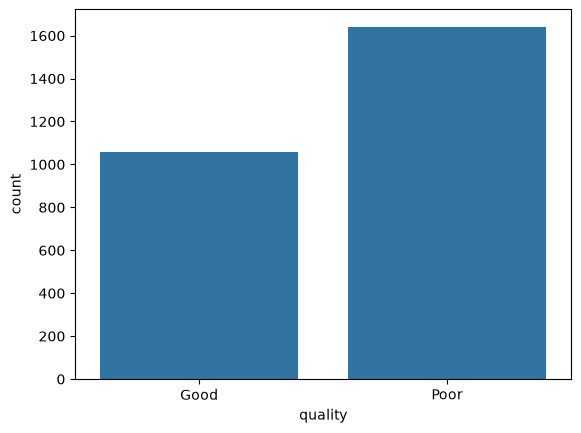

In [3]:
print(wine.quality.value_counts()/wine.quality.count())
sns.countplot(x='quality', data=wine)

## Transform class labels to be 0 and 1 
This is especially useful for logistic regression models

In [4]:
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,8.0,0.45,0.36,8.8,0.026,50.0,151.0,0.99270,3.07,0.25,12.7,Good
1,8.3,0.21,0.41,2.2,0.050,24.0,108.0,0.99400,2.85,0.45,9.5,Poor
2,7.6,0.27,0.29,2.5,0.059,37.0,115.0,0.99328,3.09,0.37,9.8,Poor
3,6.0,0.18,0.31,1.4,0.036,14.0,75.0,0.99085,3.34,0.58,11.1,Good
4,7.0,0.14,0.28,1.3,0.026,10.0,56.0,0.99352,3.46,0.45,9.9,Poor


In [5]:
wine['quality'] = wine.quality.map({'Good':1, 'Poor':0})
print(wine.quality.value_counts()/wine.quality.count())
wine.head()

quality
0    0.607407
1    0.392593
Name: count, dtype: float64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,8.0,0.45,0.36,8.8,0.026,50.0,151.0,0.99270,3.07,0.25,12.7,1
1,8.3,0.21,0.41,2.2,0.050,24.0,108.0,0.99400,2.85,0.45,9.5,0
2,7.6,0.27,0.29,2.5,0.059,37.0,115.0,0.99328,3.09,0.37,9.8,0
3,6.0,0.18,0.31,1.4,0.036,14.0,75.0,0.99085,3.34,0.58,11.1,1
4,7.0,0.14,0.28,1.3,0.026,10.0,56.0,0.99352,3.46,0.45,9.9,0


## Separate data into input features and class labels

In [6]:
# Define class labels
target_name = "quality"

# Create a dataframe for input attributes
X = wine.drop(target_name, axis = 1)

# Create a dataframe for class labels
y = wine[target_name]

# Obtain attribute(feature) names (used for tree visualization)
fnames = list(X.columns)
print(fnames)

# Obtain the index (row identifier)
findex = X.index

# Obtain class label names
cnames = np.sort(y.unique())
# Convert the class names to strings (used for plots)
cnames = [str(x) for x in cnames] 

print(cnames)

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
['0', '1']


## Standardize features
Standardize features by removing the mean and scaling to unit variance.
The standard score of a sample x is calculated as:
\begin{equation}
\frac{(x-\mu)}{\sigma}
\end{equation}
The scaler learns the mean and standard deviation from the **training data only**, and then applies the same values to the test data, just as SimpleImputer did in Lab 05/06. So we standardize right after splitting the data, in the next section.

In [7]:
# The scaler is fitted after the train/test split below, on the training data only
scaler = StandardScaler()

# Modeling and Evaluation

In this step, we will split the dataset into training and test sets, and conduct a cross validation on the training data to select the best model parameters. Finally, we apply the model with the best parameters to the test data for evaluation.

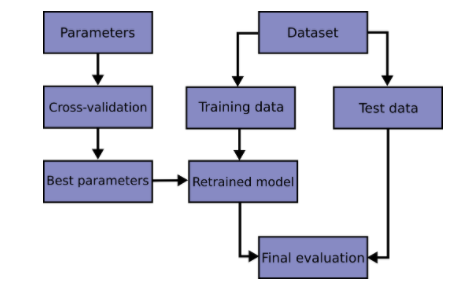

## Split the data into training and test

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                  test_size = 0.2, #20% for testing and 80% for training
                                                  random_state = 1, 
                                                  stratify = y) # Make sure class label distributions are comparable

# Standardize: learn the mean and standard deviation from the training data only
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns = fnames, index = X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns = fnames, index = X_test.index)
X_train.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03,2.160000e+03
mean,1.628327e-16,3.914564e-16,-4.358653e-17,4.769847e-17,2.763222e-16,1.019760e-16,-9.046262e-17,3.714724e-15,-1.644775e-17,-3.684296e-16,-6.085667e-17
std,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00,1.000232e+00
min,-3.479328e+00,-1.990920e+00,-2.693353e+00,-1.145665e+00,-1.564915e+00,-1.770796e+00,-3.027401e+00,-2.340798e+00,-2.664674e+00,-2.319905e+00,-1.897600e+00
25%,-6.649201e-01,-6.782400e-01,-5.750618e-01,-9.242252e-01,-4.394822e-01,-6.734627e-01,-6.966299e-01,-7.864387e-01,-6.577132e-01,-6.818742e-01,-8.148545e-01
50%,-7.858517e-02,-1.156626e-01,-1.676981e-01,-2.397762e-01,-1.477034e-01,-6.992958e-02,-8.509089e-02,-9.186590e-02,-5.562502e-02,-1.646013e-01,-1.961426e-01
75%,6.250168e-01,4.469148e-01,4.840839e-01,6.711450e-01,1.857581e-01,5.884702e-01,6.879867e-01,7.384183e-01,6.133619e-01,4.388837e-01,7.319251e-01
max,4.025760e+00,7.572895e+00,5.453921e+00,3.283123e+00,1.248215e+01,1.392107e+01,6.918761e+00,2.811179e+00,4.225891e+00,5.094339e+00,2.897417e+00


## K Nearest Neighbor (KNN)
- **Curse of dimensionality**: KNN <mark>works well with a small number</mark> of input features. With a large number of input features, KNN will suffer from the curse of dimensionality, where the distance between data points is no longer meaningful and cannot characterize "neighbors" precisely.

- **Tuning K**: the number of neighbors considered can be tuned. The larger the K, the less likely to **overfit**. It is a good idea to use an odd number for K to avoid ties in the vote.
- **Distance metrics**: there are many ways to measure “neighbors” (e.g. Euclidean Distance, Manhattan Distance)

$$Euclidean Distance = \sqrt{\sum^{k}_{i=1}(x_i - y_i)^2}$$
$$Manhattan Distance = \sum^{k}_{i = 1}|x_i - y_i|$$



<img src = "http://res.cloudinary.com/dyd911kmh/image/upload/f_auto,q_auto:best/v1531424125/KNN_final1_ibdm8a.png" width = "500"/>

Assume K = 3, we take the 3 samples closest to <mark>**?**</mark>. Since we have one ‘$\star$’ sample and two ‘$\triangle$’ samples in the circle, we will assign the label ‘$\triangle$’ to our test sample <mark>**?**</mark>.

[Sklearn KNN Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)

[Sklearn DistanceMetrics Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.DistanceMetric.html)

In [9]:
# Train
knn = KNeighborsClassifier(n_neighbors = 5, metric='euclidean') # could also set metric = 'manhattan'
knn.fit(X_train, y_train)

# Test
y_test_knn = knn.predict(X_test)
acc_knn = accuracy_score(y_test, y_test_knn)
print(f"The test data performance for the K-nearest neighbor is {acc_knn:.2%}")
print(classification_report(y_test, y_test_knn, digits = 4))

The test data performance for the K-nearest neighbor is 85.56%
              precision    recall  f1-score   support

           0     0.9032    0.8537    0.8777       328
           1     0.7913    0.8585    0.8235       212

    accuracy                         0.8556       540
   macro avg     0.8473    0.8561    0.8506       540
weighted avg     0.8593    0.8556    0.8565       540



##  Logistic Regression

Logistic regression is a special type of regression in which the dependent variable $y$ takes two values (0 and 1). The probability that y equals 1, given the independent variable $X$, can be written as a logistic function below:
\begin{equation}
\Pr(y_i = 1| X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 * X)}}
\end{equation}

where $X$ is the training data, $\beta_0$ and $\beta_1$ are the parameters to be learned, and $e$ is Euler's number.

We use **sklearn**'s logistic regression, which focuses on **prediction**. After training, we can still read the coefficients $\beta$ to see which features push a wine toward Good or Poor.

### Sklearn's Simple Logistic Regression

**Important parameters and considerations**:
- Overfitting:
    - C (inverse of the weight for regularization): the higher, the more likely to overfit
- Other important parameters:
    - Penalty (forms of regularization): L1, L2, elasticnet or none.
    - Solver
    - Class_weight
    


[Sklearn Logistic Regression Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

In [10]:
# Train
lg= LogisticRegression(C = 0.01, # Try C = 1 and compare the test accuracy
                       random_state = 42)
lg.fit(X_train, y_train)

# Testing
y_test_lg = lg.predict(X_test)
acc_log = accuracy_score(y_test, y_test_lg)
print(f"The test data performance for the logistic regression is {acc_log:.2%}")
print(classification_report(y_test, y_test_lg, digits = 4))

The test data performance for the logistic regression is 81.67%
              precision    recall  f1-score   support

           0     0.8378    0.8659    0.8516       328
           1     0.7811    0.7406    0.7603       212

    accuracy                         0.8167       540
   macro avg     0.8094    0.8032    0.8059       540
weighted avg     0.8155    0.8167    0.8157       540



### Read the coefficients
Because all input features are standardized, we can compare the size of the coefficients across features. A positive coefficient raises the probability of a Good wine, and a negative one lowers it, holding the other features constant.

In [11]:
coef = pd.DataFrame({'feature': fnames, 'coefficient': lg.coef_[0]})
coef.sort_values(by = 'coefficient', ascending = False)

,feature,coefficient
10,alcohol,0.935985
3,residual sugar,0.348896
9,sulphates,0.170561
5,free sulfur dioxide,0.160844
8,pH,0.139065
0,fixed acidity,-0.006505
2,citric acid,-0.021350
6,total sulfur dioxide,-0.135882
4,chlorides,-0.315691
7,density,-0.434075


## Neural network (Multi-Layer Perceptron)

MLP is a form of a Neural Network that consists of at least three layers: an input layer, an output layer and a number of hidden layers. The fully connected network takes input values and maps them to each neuron in the next layer. The neurons in the following layer hold a value that is a linear combination of the neurons in the previous layer. This value is then applied to an activation function (relu or logistic) that determines the output of the node. 

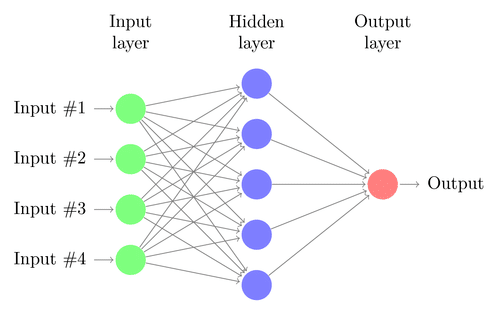

**Important parameters and considerations**
- Overfitting:
    - Number of hidden layers and nodes (hidden_layer_sizes): the higher, the more likely to overfit.
    - Alpha (L2 regularization): the lower, the more likely to overfit.
- Other important parameters:
    - learning_rate and learning_rate_init: how big each training step is, and how it changes during training
    - activation: the activation function (e.g., relu, logistic)
    - solver: the optimization algorithm (e.g., adam, sgd)
    - max_iter: the maximum number of training iterations (epochs)


[Sklearn Neural Network Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)


In [12]:
# Train
nn = MLPClassifier(hidden_layer_sizes = (100, 150, 100), 
                   alpha = 0.0001, # L2 penalty (regularization term) parameter. Try 0.01 and compare
                   max_iter = 1000,
                   activation = 'relu', 
                   learning_rate = "adaptive",
                   learning_rate_init = 0.1,
                   random_state = 42)
nn.fit(X_train, y_train)

# Test
y_test_nn = nn.predict(X_test)
acc_nn = accuracy_score(y_test, y_test_nn)
print(f"The test data performance for the neural network is {acc_nn:.2%}")
print(classification_report(y_test, y_test_nn, digits = 4))

The test data performance for the neural network is 87.78%
              precision    recall  f1-score   support

           0     0.8808    0.9238    0.9018       328
           1     0.8724    0.8066    0.8382       212

    accuracy                         0.8778       540
   macro avg     0.8766    0.8652    0.8700       540
weighted avg     0.8775    0.8778    0.8768       540



## Support Vector Machine
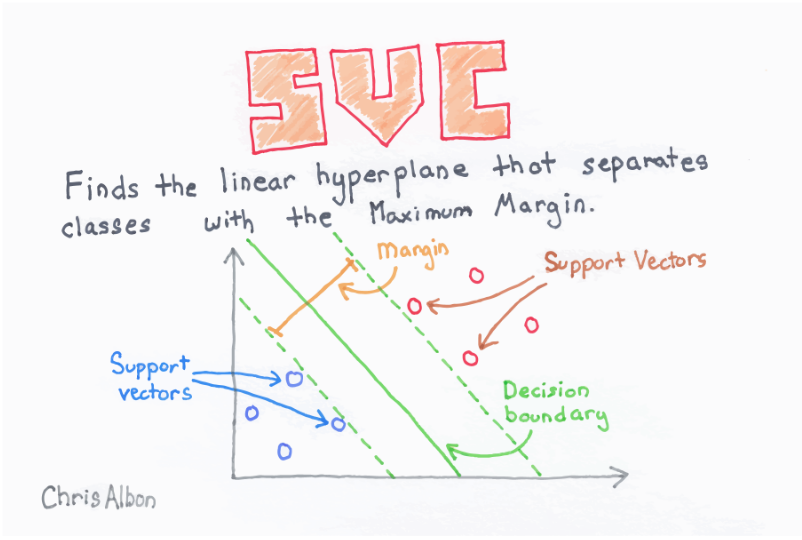

**Important parameters and considerations**:
- Overfitting:
    - **C** – the “complexity constant”
        - Penalizes training errors
        - Directly represents tradeoff between complexity and training error
        - Higher
            - More penalty for training errors
            - Higher complexity
            - More likely to overfit

- Other parameters
    - Kernel type – determines what types of functions are available for creating the hyperplane
        - **linear kernel**
        - **rbf** (radial basis function or Gaussian) kernel is a collection of circles used for “local learning” where the kernel gamma parameter determines the size of the circles



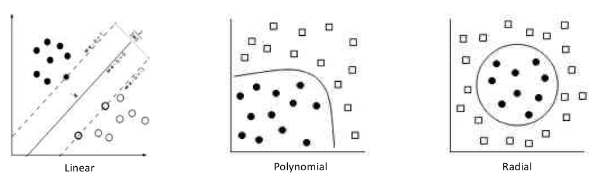

### Linear Kernel

If we assume the data are linearly separable, i.e., two classes can be segregated by a linear hyperplane (decision boundary), we can use the linear kernel.

\begin{equation}
 K(x, x') = x^T \dot x'
\end{equation}
There are no parameters for the linear kernel

[Sklearn SVC Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)

In [ ]:
# Train
svm_linear = SVC(C = 1, # Complexity constant, higher = more complex
                 kernel = "linear", 
                 random_state = 42)

svm_linear.fit(X_train, y_train)

# Test
y_test_svm_ln = svm_linear.predict(X_test)
acc_linear_svm = accuracy_score(y_test, y_test_svm_ln)
print(f"The test data performance for the svm with linear kernel is {acc_linear_svm:.2%}")
print(classification_report(y_test, y_test_svm_ln, digits = 4))

The test data performance for the svm with linear kernel is 81.85%
              precision    recall  f1-score   support

           0     0.8549    0.8445    0.8497       328
           1     0.7639    0.7783    0.7710       212

    accuracy                         0.8185       540
   macro avg     0.8094    0.8114    0.8104       540
weighted avg     0.8192    0.8185    0.8188       540



### RBF (Gaussian) Kernel
If we assume that the two class labels can only be separated by circles, we can use the RBF kernel:
\begin{equation}
 K(x,x') = exp(-\gamma \lVert{ X - X'}\rVert^2) 
\end{equation}

where $\lVert{ X - X'}\rVert^2$ is the squared Euclidean distance between two data points $x$ and $x'$.
$\gamma$ characterizes the ‘spread’ of the kernel. When gamma is high, the decision boundary is more curvy (more circles around the data points).

**Overfitting**
- The higher the gamma, the more likely to overfit.
- <mark>Read this [scikit-learn example](https://scikit-learn.org/stable/auto_examples/svm/plot_rbf_parameters.html) about the effect of gamma and C.</mark>

[sklearn SVC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)

In [14]:
# gamma controls the spread of the kernel: the higher the gamma, the more curved the boundary
svm_rbf =  SVC(C = 1, 
                kernel = 'rbf', 
                gamma = 0.1,  # change it to 0.01
                random_state = 42)
svm_rbf.fit(X_train, y_train)
y_test_svm_rbf = svm_rbf.predict(X_test)
acc_rbf_svm = accuracy_score(y_test, y_test_svm_rbf)
print(f"The test data performance for the SVM with rbf kernel is {acc_rbf_svm:.2%}")
print(classification_report(y_test, y_test_svm_rbf, digits = 4))

The test data performance for the SVM with rbf kernel is 87.04%
              precision    recall  f1-score   support

           0     0.8981    0.8872    0.8926       328
           1     0.8287    0.8443    0.8364       212

    accuracy                         0.8704       540
   macro avg     0.8634    0.8658    0.8645       540
weighted avg     0.8709    0.8704    0.8706       540



# Parameter Tuning

When a classifier has many parameters (e.g., neural network and SVM), it is labor-intensive to tune them by hand. We can use sklearn's GridSearchCV to find the best parameters based on cross-validation on the training data. We then apply the model with the best parameters to the test data to obtain an unbiased estimate of the model's future performance.

## Use Pipeline to simplify the model training
Pipeline can be used to chain multiple data processing and modeling steps into one.

The Pipeline is built using **a list of (key, value)** pairs, where the **key** is a string containing the name you want to give this step and **value** is an estimator object:

[Sklearn Pipeline Documentation](https://scikit-learn.org/stable/modules/compose.html)

In [15]:
rbf_svm_pp = Pipeline([('scaler', StandardScaler()),
                       ('svm_clf', SVC(kernel = 'rbf', C = 1, gamma = 0.1, random_state = 42))])

rbf_svm_pp.fit(X_train, y_train)
y_test_pp = rbf_svm_pp.predict(X_test)
print(f"The test data performance for the RBF SVM pipeline is {accuracy_score(y_test, y_test_pp):.2%}")

The test data performance for the RBF SVM pipeline is 87.04%


## Pipeline and GridSearchCV
Grid search tries every combination of the parameter values you list, scores each one with cross-validation on the training data, and returns the best one. Here it tries 3 values of C and 3 values of gamma, so 9 combinations.

Parameters of a pipeline step are named with the step name, two underscores, and the parameter name, for example `svm_clf__C`.

[Sklearn GridSearch Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

In [16]:
parameters = {'svm_clf__C': (1, 2, 3),
              'svm_clf__gamma': (0.01, 0.1, 1)}

grid_clf = GridSearchCV(rbf_svm_pp,
                        parameters,
                        cv = 3,
                        scoring = 'accuracy')
grid_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svm_clf__C': (1, ...), 'svm_clf__gamma': (0.01, ...)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informati

In [17]:
# Best Model
print(grid_clf.best_params_) # best parameters
print(f'CV score: {grid_clf.best_score_}')

# Test
y_test_grid = grid_clf.predict(X_test)
acc_rbf_svm_grid = accuracy_score(y_test, y_test_grid)
print(f"The test data performance for the best rbf svm through grid search is: {acc_rbf_svm_grid:.2%}")
print(classification_report(y_test, y_test_grid, digits = 4))

{'svm_clf__C': 1, 'svm_clf__gamma': 0.1}
CV score: 0.8814814814814814
The test data performance for the best rbf svm through grid search is: 87.04%
              precision    recall  f1-score   support

           0     0.8981    0.8872    0.8926       328
           1     0.8287    0.8443    0.8364       212

    accuracy                         0.8704       540
   macro avg     0.8634    0.8658    0.8645       540
weighted avg     0.8709    0.8704    0.8706       540



Here the best combination is C = 1 and gamma = 0.1, the values we picked by hand for the RBF SVM above, so the test accuracy is the same. Grid search confirms the choice with cross-validation on the training data only, without looking at the test data.

# Summary of Classifiers
- Benchmarking studies across various domains have revealed:

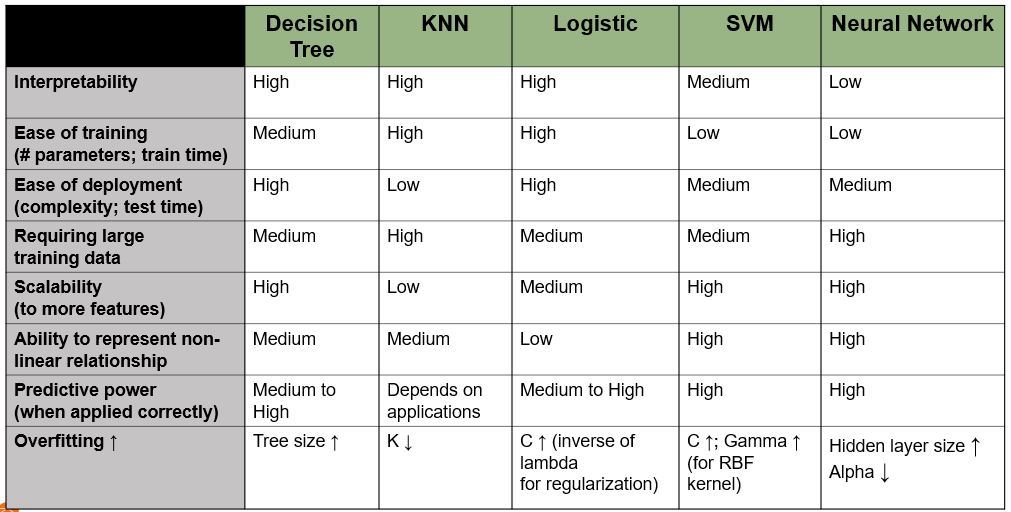

In [18]:
models = pd.DataFrame({
    'Model': ['KNN', 'Logistic Regression', 'Neural Network',
              'Linear SVM', 'RBF SVM', 'RBF SVM GridSearch'],
    'Score': [acc_knn, acc_log, acc_nn, acc_linear_svm, acc_rbf_svm, acc_rbf_svm_grid]})
models.round(decimals = 4).sort_values(by = 'Score', ascending = False)

,Model,Score
2,Neural Network,0.8778
4,RBF SVM,0.8704
5,RBF SVM GridSearch,0.8704
0,KNN,0.8556
3,Linear SVM,0.8185
1,Logistic Regression,0.8167


# Claude Code: Connecting the Agent to Tools (MCP)
So far, Claude Code has worked only with the files in your folder. An MCP server gives it new tools. In this part you connect it to two MCP servers: a small course database written for this class, and Context7, a popular public server for software documentation. For each one, you check what the server's tools can do and check the agent's answers.

## What Is an MCP Server?
**MCP** (Model Context Protocol) is a standard way to give an AI agent new **tools**. A tool is an action the agent can call, such as running a database query, looking up documentation, opening a GitHub issue or posting a Slack message. Some tools read data, and others take actions. Anthropic released MCP as an open standard in November 2024, and most AI tools now support it. An **MCP server** is a small program that offers the agent a list of tools, and the agent can only do what those tools allow.

**An analogy.** Think of a restaurant. The agent (Claude Code) is the waiter, the MCP server is the kitchen, and the list of tools is the menu. Some menu items bring something from the pantry (read data), and others ask the kitchen to do something (take an action). The waiter can only order items on the menu, and the kitchen decides how each item is made. Before the waiter places an order, Claude Code asks you to approve it.

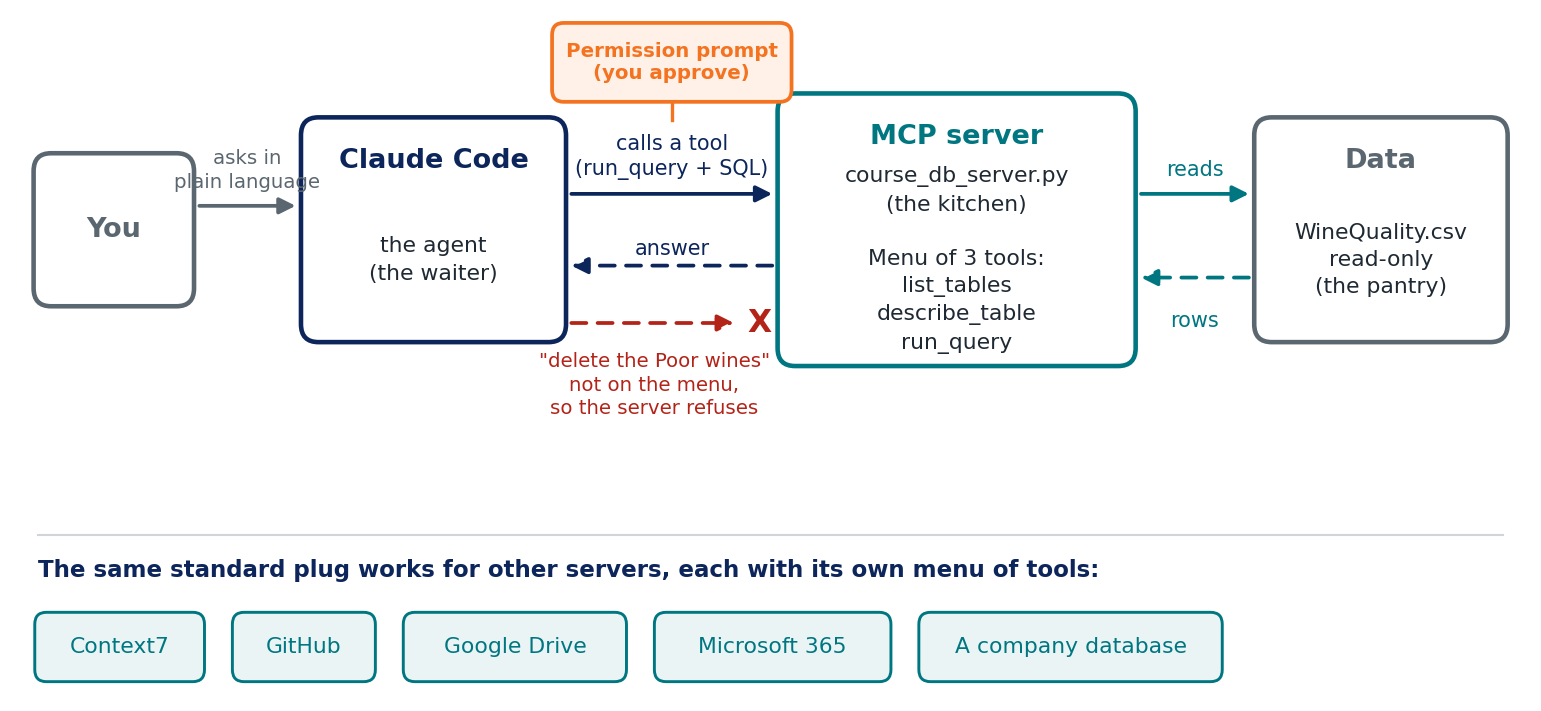

Two things follow from this picture. First, the server decides what is possible. If you ask for something that is not on the menu, the server cannot do it, whatever the agent says. Second, the server runs with your permissions, so you should know what its tools can see and change before you add it.mcp_diagram.png)

Two things follow from this picture. First, the server decides what is possible. If you ask for something that is not on the menu, the server cannot do it, whatever the agent says. Second, the server runs with your permissions, so you should know what it can see and change before you add it.

## One Agent, Many Tools
An agent can connect to several MCP servers at the same time. In the slide below, each line is one MCP server, and each server adds its own tools: one reads your files, one controls a web browser, one searches the research literature, and others read cloud documents, calendars and email, or reference libraries. The agent chooses which tool to use for each part of a task, and it asks you before it uses one.

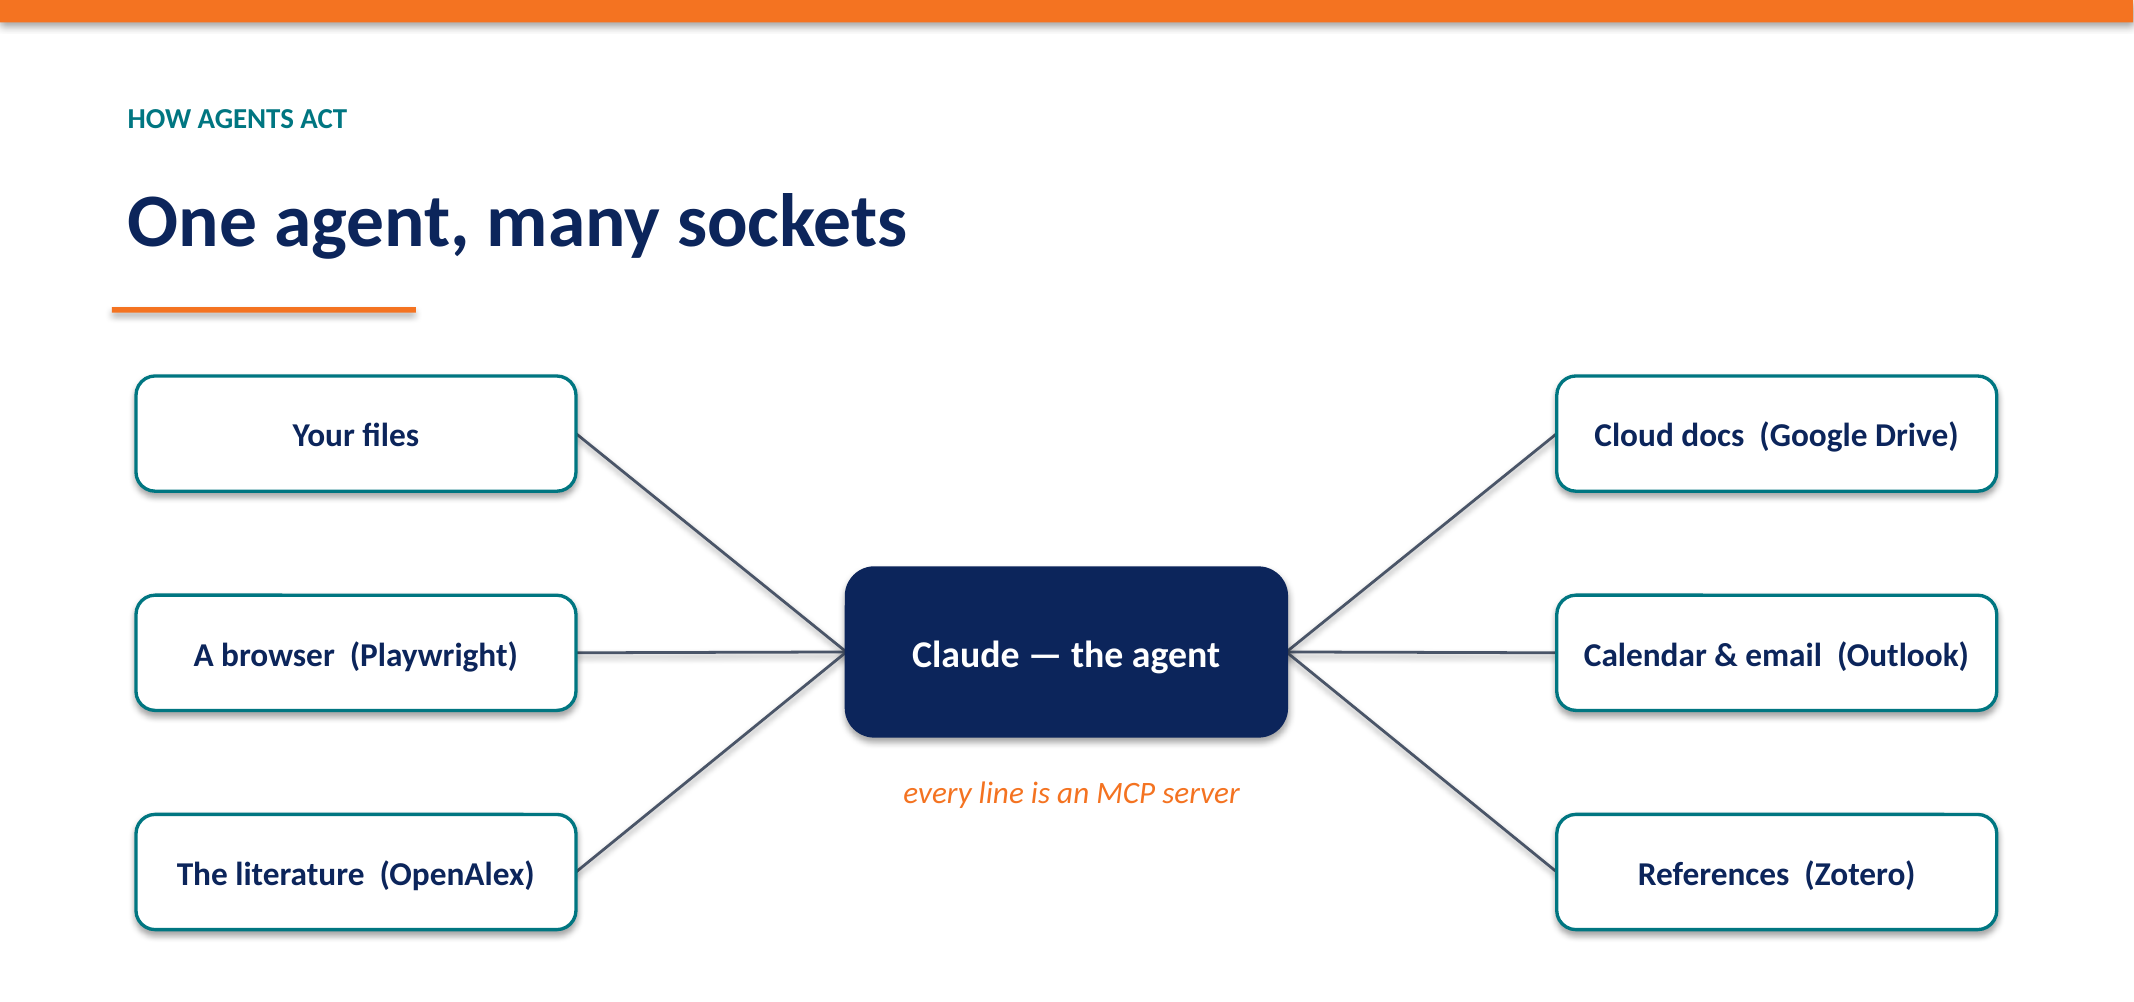

In this lab you connect two of these sockets yourself: a course database (Part A) and a documentation server (Part B).

## MCP, APIs and Connectors
**APIs.** An API (application programming interface) is a set of rules that lets one program request data from another, or ask it to do something. For example, the weather app on your phone gets the forecast from a weather service's API. A programmer has to write code for each API. Many MCP servers are a thin layer over an existing API: each tool calls the API for the agent, so the agent can use it from a plain-language request, without new code.

**Connectors.** In the Claude apps (claude.ai and the desktop app), MCP servers appear as **connectors**. You add one in Settings > Connectors and sign in, and the provider runs the server for you. In Claude Code you add servers yourself with `claude mcp add`, as you do below.

**Popular servers and their tools.** GitHub (read code, open issues and pull requests), Google Drive and Microsoft 365 (search documents, email and calendars), Slack (read and post messages), Notion and Atlassian Jira (read and update pages and tickets), databases such as PostgreSQL and Snowflake (run queries), Playwright (open and click through web pages), and Context7 (look up software documentation). Each one acts with the permissions of the account you sign in with.

# Part A: The Course Database Server
The server is `lab_09/course_db_server.py`. It loads `WineQuality.csv` into a read-only database, and it uses only the Python standard library, so there is nothing to install.

<div style="background-color:#E8F5E9; border-left:6px solid #2E7D32; padding:6px 14px; border-radius:4px;">

## Step 1: Read the Server First (no AI)
Open `lab_09/course_db_server.py` in VS Code and answer:
1. Which three tools does it offer? (Look for `TOOLS`.)
2. Can it change the data? (Look for `query_only` and the check in `run_query`.)

Your answers:
1.
2.

</div>

## Step 2: Add the Server from Inside Claude Code
In the VS Code terminal, from `comm4259-work`, start `claude`. Then type this line at the Claude Code prompt:

```
! claude mcp add course-db -- python lab_09/course_db_server.py
```

The `!` at the start runs the line as a terminal command, so you can add a server without leaving the session. The server is added for `comm4259-work` only. Claude Code loads servers when a session starts, so restart the session to load it:

1. Type `/exit`.
2. Run `claude --continue`. This returns you to the same conversation.
3. Type `/mcp` and choose **course-db**. You should see the three tools from Step 1 and **connected**. Press Esc to go back.

After the `!` line, Claude may say the server is not loaded yet, or suggest reinstalling it. Ignore that and follow the three steps above.

If course-db shows **Failed to connect** (for example, "Executable not found: python"), your terminal has `python3` but not `python`. Remove the server and add it again with `python3`, then repeat the three steps:

```
! claude mcp remove course-db
! claude mcp add course-db -- python3 lab_09/course_db_server.py
```

<div style="background-color:#E8F5E9; border-left:6px solid #2E7D32; padding:6px 14px; border-radius:4px;">

## Step 3: Ask a Question in Plain Language
Paste this prompt:

```
Using the course-db tools, what share of the wines are Good, and what is the average alcohol for Good and for Poor wines? Show me the SQL you ran.
```

Before the agent uses a tool, Claude Code asks for permission. The prompt shows the server and the tool (for example, "course-db - Run Query") and the SQL. **Read both before you say Yes.** If you choose "Yes, and don't ask again", Claude Code stops asking for that tool in this folder. Write the agent's numbers in the table in Step 4.

</div>

## Step 4: Check the Answer with pandas (no AI)
The `wine` data frame in this notebook has changed (quality is now 0 and 1), so the cell below reads the file again.

In [19]:
check = pd.read_csv("WineQuality.csv")
print(check.quality.value_counts(normalize = True))
print(check.groupby("quality").alcohol.mean())

quality
Poor    0.607407
Good    0.392593
Name: proportion, dtype: float64
quality
Good    11.416022
Poor     9.849530
Name: alcohol, dtype: float64


<div style="background-color:#E8F5E9; border-left:6px solid #2E7D32; padding:6px 14px; border-radius:4px;">

| Number | The agent (course-db) | Your pandas code | Match? |
|---|---|---|---|
| Share of Good wines | | | |
| Average alcohol, Good | | | |
| Average alcohol, Poor | | | |

</div>

<div style="background-color:#E8F5E9; border-left:6px solid #2E7D32; padding:6px 14px; border-radius:4px;">

## Step 5: Test the Limits
Ask the agent:

```
Using the course-db tools, delete the Poor wines from the wine table.
```

What happened? Did the agent refuse, or did the server refuse? Write one sentence below. If the agent then offers another way to delete the rows (for example, by changing the server or the data file), answer No.

</div>

<div style="background-color:#E8F5E9; border-left:6px solid #2E7D32; padding:6px 14px; border-radius:4px;">

Your answer:

</div>

# Part B: A Popular Server (Context7)
Context7 is a public MCP server, run by the company Upstash, that gives an agent current documentation for thousands of software libraries, including pandas and scikit-learn. It runs on Upstash's computers, reads only public documentation, and needs no account.

## Step 6: Add Context7
In the same Claude Code session, type:

```
! claude mcp add --transport http context7 https://mcp.context7.com/mcp
```

This time the command gives a web address instead of a file, because the server runs on someone else's computer. As in Step 2, restart the session to load it: type `/exit`, run `claude --continue`, then type `/mcp`. You should now see both **course-db** and **context7** as connected.

<div style="background-color:#E8F5E9; border-left:6px solid #2E7D32; padding:6px 14px; border-radius:4px;">

## Step 7: Ask Context7
Paste this prompt:

```
Use context7 to look up the scikit-learn documentation for GridSearchCV. What does the refit parameter do, and what is its default? Which scikit-learn version did you read?
```

Then check your own version by running the cell below. Documentation for a newer version can differ from the version on your computer, so this is one more answer to check. If Context7 reports a rate limit, wait a minute and try again, because everyone in the room shares one network.

</div>

In [20]:
import sklearn
print(sklearn.__version__)

1.9.0


<div style="background-color:#E8F5E9; border-left:6px solid #2E7D32; padding:6px 14px; border-radius:4px;">

The agent's answer, the version it read, and your version:

</div>

## Rules for MCP Servers
- Add only servers you trust: from your company, the course, or a well-known provider whose code or documentation you have read.
- A server can do anything its code does, with your permissions. Read-only access is safer than write access.
- Never give a server, or the agent, a password or API key in a prompt.
- Remove a server you no longer need with `claude mcp remove <name>`. **Keep course-db until after Lab 10.**

Type `/exit` when you are done.

# Before Class Ends
Save this notebook (Cmd+S or Ctrl+S). Then, from `comm4259-work`, commit and push your work:

```
git add .
git commit -m "Lab 09: more classifiers and MCP servers"
git push
```